# RQ12 — Positive–unlabeled learning paradigm

## Scientific question

**Does explicitly modeling unlabeled proteins as unlabeled—rather than treating them as confirmed negatives—materially change positive recovery, unlabeled-protein ranking, and score behavior in phage lytic-function prediction?**

RQ12 compares the three **completed and directly matched** PU strategies:

1. `naive`
   - diagnostic P-vs-U baseline;
   - U is temporarily treated as the negative optimization class;
   - its P/U classification metrics are **observed-label diagnostics only**.

2. `baggingpu`
   - 30 internal bags;
   - each bag retains known positives and samples U as temporary negatives;
   - frozen U:P sampling ratio = 1:1.

3. `elkan_noto`
   - propensity-corrected PU learning;
   - labeling propensity `c` estimated by group-aware cross-fitting from outer-train positives only;
   - 5 folds;
   - test data are never used to estimate `c`.

### Frozen benchmark

- 2 PU universes;
- 16 R×S cells;
- 4 representations;
- 3 PU methods;
- 2 common base learners (`LR`, `XGB`);

for a total of:

\[
2\times16\times4\times3\times2 = 768
\]

completed experiment families.

## Interpretation contract

`U` means **unlabeled**, not negative.

Therefore, conventional MCC, AP, ROC-AUC, precision, specificity, etc. computed by assigning observed labels `P=1`, `U=0` are useful only as **controlled observed-label diagnostics**. They are not unbiased estimates of biological positive-vs-negative classification.

RQ12 therefore prioritizes diagnostics that are meaningful under the PU setting:

- score separation between labeled positives and U;
- percentile position of P relative to U;
- fraction of P above the U 90th / 95th / 99th score percentiles;
- score-level agreement across PU methods on the same U proteins;
- overlap of top-ranked U candidates;
- BaggingPU internal score variability;
- Elkan–Noto propensity behavior.

High-scoring U proteins are **candidate-like observations**, never asserted positives.

## Scope boundary

RQ12 asks whether the **learning paradigm itself** matters.

The following are intentionally deferred:

- detailed R/S sensitivity curves → **RQ13**;
- conservative vs broad U-universe effects → **RQ14**;
- representation × PU-method interaction → **RQ15**;
- common-test decomposition → **RQ16**;
- finite-test bootstrap uncertainty → **RQ17**;
- compute/runtime trade-offs → **RQ18**.

RQ12 may stratify by task/representation/algorithm only to assess whether a method-level conclusion is broadly consistent. It does not fully analyze those interactions here.

In [1]:
from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=FutureWarning)

pd.set_option("display.max_columns", 400)
pd.set_option("display.width", 240)
pd.set_option("display.max_rows", 400)

R_LEVELS = [90, 70, 50, 30]
S_LEVELS = [90, 70, 50, 30]

TASKS = ["pu_conservative", "pu_broad"]
METHODS = ["naive", "baggingpu", "elkan_noto"]
METHOD_LABELS = {
    "naive": "Naive P-vs-U",
    "baggingpu": "BaggingPU",
    "elkan_noto": "Elkan–Noto",
}

EXPECTED_REPS = [
    "roxy_48",
    "onehot_1024",
    "esm2_t6_8m",
    "esm2_t30_150m",
]
EXPECTED_ALGS = ["LR", "XGB"]

def find_project_root(start=None):
    start = Path.cwd() if start is None else Path(start)
    for candidate in [start, *start.parents]:
        if (
            (candidate / "results/analysis_pu/stage12b2").is_dir()
            and (candidate / "results/analysis_pu/stage12a_qc").is_dir()
        ):
            return candidate
    raise FileNotFoundError(
        "Could not locate project root containing Stage12B2 PU analysis outputs."
    )

ROOT = find_project_root()
PU_DIR = ROOT / "results/analysis_pu/stage12b2"
PU_QC = ROOT / "results/analysis_pu/stage12a_qc"
CACHE_DIR = ROOT / "results/analysis_pu/notebook_cache"
CACHE_DIR.mkdir(parents=True, exist_ok=True)

print("ROOT:", ROOT)
print("PU_DIR:", PU_DIR)

ROOT: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass
PU_DIR: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_pu/stage12b2


# 1. Load and validate Stage12B2

In [2]:
manifest_path = PU_DIR / "stage12b2_manifest.json"
if not manifest_path.is_file():
    raise FileNotFoundError(manifest_path)

manifest = json.loads(manifest_path.read_text())

print(json.dumps(manifest, indent=2))

if manifest.get("status") != "PASS":
    raise RuntimeError(
        f"Stage12B2 status is {manifest.get('status')}; RQ12 requires PASS."
    )

master = pd.read_csv(
    PU_DIR / "pu_master_results.tsv",
    sep="\t",
    low_memory=False,
)

registry = pd.read_csv(
    PU_QC / "pu_completed_registry.tsv",
    sep="\t",
    low_memory=False,
)

score_summary_stage = pd.read_csv(
    PU_DIR / "pu_score_distribution_summary.tsv",
    sep="\t",
    low_memory=False,
)

bagging_summary = pd.read_csv(
    PU_DIR / "pu_bagging_stability_summary.tsv",
    sep="\t",
    low_memory=False,
)

en_summary = pd.read_csv(
    PU_DIR / "pu_elkan_noto_summary.tsv",
    sep="\t",
    low_memory=False,
)

method_concordance = pd.read_csv(
    PU_DIR / "pu_method_score_concordance.tsv",
    sep="\t",
    low_memory=False,
)

print("Master rows:", len(master))
print("Registry rows:", len(registry))
print("Expected:", 768)
assert len(master) == 768
assert len(registry) == 768

{
  "stage": "12B2-PU",
  "status": "PASS",
  "experiment_families": 768,
  "diagnostic_metrics": [
    "p_recall_above_u_q90",
    "p_recall_above_u_q95",
    "p_recall_above_u_q99"
  ],
  "primary_diagnostic_metric": "p_recall_above_u_q90",
  "cross_representation_test_failures": 0,
  "interpretation": "PU performance metrics are observed-label diagnostics. U is not a confirmed negative class."
}
Master rows: 768
Registry rows: 768
Expected: 768


In [3]:
required = {
    "task", "R", "S", "representation", "method", "algorithm"
}
missing = required - set(master.columns)
if missing:
    raise KeyError(f"pu_master_results.tsv missing {sorted(missing)}")

print("Tasks:", sorted(master["task"].unique()))
print("Methods:", sorted(master["method"].unique()))
print("Representations:", sorted(master["representation"].unique()))
print("Algorithms:", sorted(master["algorithm"].unique()))

coverage = (
    master.groupby(["task", "R", "S", "representation", "algorithm"])
    ["method"]
    .nunique()
)

display(coverage.value_counts().sort_index())
assert coverage.eq(3).all()

expected_matched_cells = 2 * 16 * 4 * 2
print("Matched task×R×S×rep×algorithm cells:", len(coverage))
print("Expected:", expected_matched_cells)
assert len(coverage) == expected_matched_cells

Tasks: ['pu_broad', 'pu_conservative']
Methods: ['baggingpu', 'elkan_noto', 'naive']
Representations: ['esm2_t30_150m', 'esm2_t6_8m', 'onehot_1024', 'roxy_48']
Algorithms: ['LR', 'XGB']


method
3    256
Name: count, dtype: int64

Matched task×R×S×rep×algorithm cells: 256
Expected: 256


# 2. Detect observed-label diagnostics

The notebook uses the same **semantic numeric-metric detection** strategy as Stage12B2 instead of assuming one exact prefix such as `observed_mcc` or `observed_label_mcc`.

In [4]:
def safe_numeric_observed_metrics(df):
    """
    Mirror the robust metric detection used by Stage12B2.

    PU outputs have existed with several valid naming conventions
    (e.g. observed_mcc, observed_label_mcc, diagnostic__observed_mcc).
    We therefore detect numeric diagnostic columns by semantic tokens
    instead of requiring exact column names.
    """
    metric_tokens = (
        "mcc",
        "average_precision",
        "roc_auc",
        "auroc",
        "balanced_accuracy",
        "macro_f1",
        "weighted_f1",
        "precision",
        "recall",
        "specificity",
        "f1",
        "brier",
        "log_loss",
    )

    exact_ap_names = {
        "ap",
        "observed_ap",
        "observed_label_ap",
    }

    metrics = []

    for column in df.columns:
        if not pd.api.types.is_numeric_dtype(df[column]):
            continue

        name = str(column).lower()

        if (
            name in {"r", "s", "c", "n_bags", "u_p_ratio", "crossfit_folds"}
            or name.startswith("manifest__")
            or "seconds" in name
            or "runtime" in name
            or name.startswith("n_")
            or name.endswith("_count")
            or "clipping_fraction" in name
            or "score_std" in name
        ):
            continue

        if (
            name in exact_ap_names
            or any(token in name for token in metric_tokens)
        ):
            metrics.append(column)

    return metrics


OBS_METRICS = safe_numeric_observed_metrics(master)

def pick_metric_by_token(metrics, tokens):
    for token in tokens:
        exact = [
            m for m in metrics
            if str(m).lower() == token
        ]
        if exact:
            return exact[0]

    for token in tokens:
        hits = [
            m for m in metrics
            if token in str(m).lower()
        ]
        if hits:
            return hits[0]

    return None


OBS_MCC = pick_metric_by_token(
    OBS_METRICS,
    ["observed_label_mcc", "observed_mcc", "mcc"],
)
OBS_AP = pick_metric_by_token(
    OBS_METRICS,
    [
        "observed_label_average_precision",
        "observed_average_precision",
        "observed_label_ap",
        "observed_ap",
        "average_precision",
        "ap",
    ],
)
OBS_AUC = pick_metric_by_token(
    OBS_METRICS,
    [
        "observed_label_roc_auc",
        "observed_roc_auc",
        "roc_auc",
        "auroc",
    ],
)
OBS_BA = pick_metric_by_token(
    OBS_METRICS,
    [
        "observed_label_balanced_accuracy",
        "observed_balanced_accuracy",
        "balanced_accuracy",
    ],
)
OBS_F1 = pick_metric_by_token(
    OBS_METRICS,
    [
        "observed_label_f1",
        "observed_f1",
        "f1",
    ],
)

# Prefer an MCC-like observed diagnostic, but do not require one:
# observed-label metrics are supporting diagnostics in RQ12, not the primary PU evidence.
OBS_PRIMARY = (
    OBS_MCC
    or OBS_AP
    or OBS_AUC
    or (OBS_METRICS[0] if OBS_METRICS else None)
)

print("All master columns:")
print(list(master.columns))

print("\nObserved-label diagnostics detected:")
for c in OBS_METRICS:
    print(" ", c)

print("\nSelected supporting observed-label diagnostic:", OBS_PRIMARY)

if not OBS_METRICS:
    print(
        "WARNING: no observed-label diagnostic columns were detected in "
        "pu_master_results.tsv. RQ12 will proceed using PU-native score "
        "diagnostics; observed-label comparison sections will be skipped."
    )

All master columns:
['experiment_id', 'task', 'R', 'S', 'representation', 'method', 'algorithm', 'n', 'n_p', 'n_u', 'median_p_score', 'median_u_score', 'u_q90', 'u_q95', 'u_q99', 'p_recall_above_u_q90', 'p_recall_above_u_q95', 'p_recall_above_u_q99', 'fraction_u_ge_0_5', 'fraction_p_ge_0_5', 'base_config', 'fit_seconds', 'prediction_seconds', 'n_bags', 'u_p_ratio', 'median_test_score_std', 'mean_test_score_std', 'manifest__n_bags', 'manifest__u_p_ratio', 'c', 'crossfit_folds', 'corrected_score_clipping_fraction', 'manifest__c', 'manifest__clipping_fraction', 'manifest__crossfit_folds']

Observed-label diagnostics detected:
  p_recall_above_u_q90
  p_recall_above_u_q95
  p_recall_above_u_q99

Selected supporting observed-label diagnostic: p_recall_above_u_q90


Observed-label diagnostics are retained as supporting evidence because all three methods are evaluated on the same frozen P/U test within each matched cell.

They must **never** be described as biological specificity or true-negative discrimination.

# 3. Recompute PU-native score diagnostics directly from frozen outer-test scores

In [5]:
registry_required = {
    "experiment_id", "task", "R", "S",
    "representation", "method", "algorithm", "path"
}
missing = registry_required - set(registry.columns)
if missing:
    raise KeyError(f"PU registry missing {sorted(missing)}")

def detect_score_col(df):
    for c in ["score_positive", "score", "corrected_score", "probability"]:
        if c in df.columns:
            return c
    raise KeyError(
        f"No score column found in outer_test_scores.parquet; columns={list(df.columns)}"
    )

def percentile_against_u(values, u_sorted):
    values = np.asarray(values, dtype=float)
    u_sorted = np.asarray(u_sorted, dtype=float)
    if len(u_sorted) == 0:
        return np.full(len(values), np.nan)
    # Fraction of U scores <= each P score.
    return np.searchsorted(
        u_sorted,
        values,
        side="right",
    ) / len(u_sorted)

def tie_fraction(values, threshold):
    values = np.asarray(values, dtype=float)
    if len(values) == 0:
        return np.nan
    return float(np.mean(np.isclose(values, threshold, rtol=0.0, atol=1e-12)))

native_rows = []

for row in registry.itertuples(index=False):
    score_path = Path(row.path) / "outer_test_scores.parquet"
    if not score_path.is_file():
        raise FileNotFoundError(score_path)

    df = pd.read_parquet(score_path)
    if "observed_role" not in df.columns:
        raise KeyError(f"{score_path}: missing observed_role")

    score_col = detect_score_col(df)
    scores = pd.to_numeric(df[score_col], errors="coerce")
    roles = df["observed_role"].astype(str).str.upper()

    p = scores[roles.eq("P")].dropna().to_numpy(dtype=float)
    u = scores[roles.eq("U")].dropna().to_numpy(dtype=float)

    if len(p) == 0 or len(u) == 0:
        raise RuntimeError(
            f"{score_path}: need both P and U scores; nP={len(p)}, nU={len(u)}"
        )

    u_sorted = np.sort(u)
    u90, u95, u99 = np.quantile(u, [0.90, 0.95, 0.99])
    p_percentiles = percentile_against_u(p, u_sorted)

    row_out = {
        "experiment_id": row.experiment_id,
        "task": row.task,
        "R": int(row.R),
        "S": int(row.S),
        "representation": row.representation,
        "method": row.method,
        "algorithm": row.algorithm,
        "n_P_test": len(p),
        "n_U_test": len(u),
        "median_P_score": float(np.median(p)),
        "median_U_score": float(np.median(u)),
        "median_score_gap_P_minus_U": float(np.median(p) - np.median(u)),
        "mean_P_percentile_vs_U": float(np.mean(p_percentiles)),
        "median_P_percentile_vs_U": float(np.median(p_percentiles)),

        # Canonical recovery semantics: match trainer implementation (>= quantile).
        "fraction_P_above_U90": float(np.mean(p >= u90)),
        "fraction_P_above_U95": float(np.mean(p >= u95)),
        "fraction_P_above_U99": float(np.mean(p >= u99)),

        # Strict variants expose how much recovery is carried by boundary ties.
        "fraction_P_strictly_above_U90": float(np.mean(p > u90)),
        "fraction_P_strictly_above_U95": float(np.mean(p > u95)),
        "fraction_P_strictly_above_U99": float(np.mean(p > u99)),

        "fraction_U_score_ge_050": float(np.mean(u >= 0.5)),
        "fraction_P_score_ge_050": float(np.mean(p >= 0.5)),
        "U_q90": float(u90),
        "U_q95": float(u95),
        "U_q99": float(u99),

        # Tie diagnostics at the quantile boundary.
        "U_tie_fraction_at_q90": tie_fraction(u, u90),
        "U_tie_fraction_at_q95": tie_fraction(u, u95),
        "U_tie_fraction_at_q99": tie_fraction(u, u99),
        "P_tie_fraction_at_Uq90": tie_fraction(p, u90),
        "P_tie_fraction_at_Uq95": tie_fraction(p, u95),
        "P_tie_fraction_at_Uq99": tie_fraction(p, u99),

        # Explicit ceiling diagnostics, critical for Elkan–Noto clipping.
        "U_fraction_at_score_1": float(np.mean(np.isclose(u, 1.0, rtol=0.0, atol=1e-12))),
        "P_fraction_at_score_1": float(np.mean(np.isclose(p, 1.0, rtol=0.0, atol=1e-12))),
    }

    # Difference between canonical >= and strict > recovery is exactly
    # the fraction of P tied at the U quantile boundary.
    for q in [90, 95, 99]:
        row_out[f"P_recovery_tie_component_U{q}"] = (
            row_out[f"fraction_P_above_U{q}"]
            - row_out[f"fraction_P_strictly_above_U{q}"]
        )

    native_rows.append(row_out)

native = pd.DataFrame(native_rows)

print("PU-native diagnostic rows:", len(native))
assert len(native) == 768
display(native.head())

PU-native diagnostic rows: 768


,experiment_id,task,R,S,representation,method,algorithm,n_P_test,n_U_test,median_P_score,median_U_score,median_score_gap_P_minus_U,mean_P_percentile_vs_U,median_P_percentile_vs_U,fraction_P_above_U90,fraction_P_above_U95,fraction_P_above_U99,fraction_P_strictly_above_U90,fraction_P_strictly_above_U95,fraction_P_strictly_above_U99,fraction_U_score_ge_050,fraction_P_score_ge_050,U_q90,U_q95,U_q99,U_tie_fraction_at_q90,U_tie_fraction_at_q95,U_tie_fraction_at_q99,P_tie_fraction_at_Uq90,P_tie_fraction_at_Uq95,P_tie_fraction_at_Uq99,U_fraction_at_score_1,P_fraction_at_score_1,P_recovery_tie_component_U90,P_recovery_tie_component_U95,P_recovery_tie_component_U99
0,PU__pu_broad__R90__S90__roxy_48__naive__LR,pu_broad,90,90,roxy_48,naive,LR,1428,64386,0.842071,0.125035,0.717037,0.913919,0.969279,0.759804,0.606443,0.263305,0.759804,0.606443,0.263305,0.182928,0.867647,0.664297,0.787535,0.916668,0.0,0.00000,0.00000,0.0,0.000000,0.000000,0.00000,0.000000,0.0,0.000000,0.000000
1,PU__pu_broad__R90__S90__roxy_48__naive__XGB,pu_broad,90,90,roxy_48,naive,XGB,1428,64386,0.896035,0.003444,0.892591,0.952163,0.993935,0.887955,0.814426,0.585434,0.887955,0.814426,0.585434,0.035256,0.768908,0.152671,0.366174,0.833592,0.0,0.00000,0.00000,0.0,0.000000,0.000000,0.00000,0.000000,0.0,0.000000,0.000000
2,PU__pu_broad__R90__S90__roxy_48__baggingpu__LR,pu_broad,90,90,roxy_48,baggingpu,LR,1428,64386,0.843071,0.127132,0.715939,0.914066,0.969512,0.757703,0.607843,0.264006,0.757703,0.607843,0.264006,0.184419,0.866947,0.666161,0.788119,0.916082,0.0,0.00000,0.00000,0.0,0.000000,0.000000,0.00000,0.000000,0.0,0.000000,0.000000
3,PU__pu_broad__R90__S90__roxy_48__baggingpu__XGB,pu_broad,90,90,roxy_48,baggingpu,XGB,1428,64386,0.974142,0.024552,0.949590,0.952396,0.993089,0.876050,0.799720,0.567927,0.876050,0.799720,0.567927,0.108564,0.881653,0.534183,0.771410,0.961027,0.0,0.00000,0.00000,0.0,0.000000,0.000000,0.00000,0.000000,0.0,0.000000,0.000000
4,PU__pu_broad__R90__S90__roxy_48__elkan_noto__LR,pu_broad,90,90,roxy_48,elkan_noto,LR,1428,64386,1.000000,0.163790,0.836210,0.925649,1.000000,0.759804,0.642157,0.642157,0.759804,0.000000,0.000000,0.256593,0.912465,0.870198,1.000000,1.000000,0.0,0.05919,0.05919,0.0,0.642157,0.642157,0.05919,0.642157,0.0,0.642157,0.642157


The primary recovery diagnostics use the **same canonical semantics as the frozen trainer**:

\[
\mathrm{recovery}_{q} = \Pr(s_P \ge Q_q(s_U)).
\]

The inclusive `>=` operator is important because Elkan–Noto probability correction can create a ceiling plateau at score 1.0 after clipping.

RQ12 therefore reports both:

- **canonical inclusive recovery** (`P >= U quantile`);
- **strict recovery** (`P > U quantile`);
- the difference between them, which quantifies how much of the apparent recovery is carried by **ties at the quantile boundary**.

Raw score gaps remain descriptive because Elkan–Noto explicitly rescales probabilities.

# 4. Overall PU-method behavior

In [6]:
native_method_summary = (
    native.groupby("method")
    .agg(
        n=("experiment_id", "size"),
        median_P_percentile=("median_P_percentile_vs_U", "median"),
        mean_P_percentile=("median_P_percentile_vs_U", "mean"),
        P_above_U90=("fraction_P_above_U90", "median"),
        P_above_U95=("fraction_P_above_U95", "median"),
        P_above_U99=("fraction_P_above_U99", "median"),
        median_P_score=("median_P_score", "median"),
        median_U_score=("median_U_score", "median"),
        median_score_gap=("median_score_gap_P_minus_U", "median"),
        U_selected_050=("fraction_U_score_ge_050", "median"),
    )
    .reindex(METHODS)
)

display(native_method_summary)

,n,median_P_percentile,mean_P_percentile,P_above_U90,P_above_U95,P_above_U99,median_P_score,median_U_score,median_score_gap,U_selected_050
method,,,,,,,,,,
naive,256,0.993557,0.970393,0.867555,0.805159,0.584050,0.899342,0.001522,0.855712,0.034108
baggingpu,256,0.993295,0.983808,0.867149,0.798217,0.575905,0.976879,0.032992,0.940302,0.108984
elkan_noto,256,1.000000,0.980516,0.867555,0.805159,0.683147,1.000000,0.002225,0.994317,0.053280


# 4b. Quantile-boundary ties and Elkan–Noto ceiling audit

Elkan–Noto rescales scores by the cross-fitted labeling propensity and clips corrected probabilities to `[0,1]`. When many U proteins reach exactly `1.0`, the nominal U99 boundary can fall inside a large tie plateau. Canonical recovery remains valid under the trainer's `>=` definition, but the extreme ranking tail is no longer fully resolved.


In [7]:
tie_audit = (
    native.groupby("method")
    .agg(
        U_q99_median=("U_q99", "median"),
        U_tie_q99_median=("U_tie_fraction_at_q99", "median"),
        U_tie_q95_median=("U_tie_fraction_at_q95", "median"),
        U_ceiling_1_median=("U_fraction_at_score_1", "median"),
        P_ceiling_1_median=("P_fraction_at_score_1", "median"),
        canonical_P_ge_U99=("fraction_P_above_U99", "median"),
        strict_P_gt_U99=("fraction_P_strictly_above_U99", "median"),
        U99_recovery_tie_component=("P_recovery_tie_component_U99", "median"),
    )
    .reindex(METHODS)
)

display(tie_audit)

print(
    "Interpretation: a large gap between canonical P>=U99 and strict P>U99 "
    "means the U99 recovery is materially supported by score ties at the "
    "quantile boundary, not by resolved ordering above that boundary."
)

,U_q99_median,U_tie_q99_median,U_tie_q95_median,U_ceiling_1_median,P_ceiling_1_median,canonical_P_ge_U99,strict_P_gt_U99,U99_recovery_tie_component
method,,,,,,,,
naive,0.829838,0.000000,0.0,0.000000,0.000000,0.584050,0.584050,0.000000
baggingpu,0.945118,0.000000,0.0,0.000000,0.000000,0.575905,0.575905,0.000000
elkan_noto,1.000000,0.021891,0.0,0.021891,0.664199,0.683147,0.000000,0.560367


Interpretation: a large gap between canonical P>=U99 and strict P>U99 means the U99 recovery is materially supported by score ties at the quantile boundary, not by resolved ordering above that boundary.


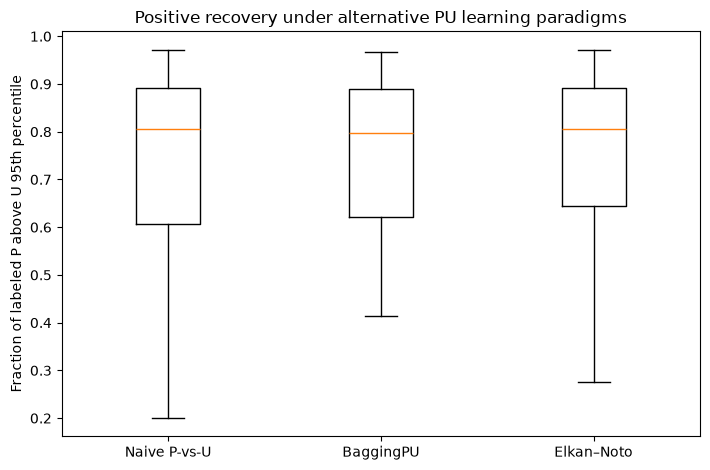

In [8]:
fig, ax = plt.subplots(figsize=(7.2, 4.8))

data = [
    native.loc[
        native["method"].eq(m),
        "fraction_P_above_U95",
    ].dropna().to_numpy()
    for m in METHODS
]

ax.boxplot(
    data,
    tick_labels=[METHOD_LABELS[m] for m in METHODS],
    showfliers=False,
)
ax.set_ylabel("Fraction of labeled P above U 95th percentile")
ax.set_title("Positive recovery under alternative PU learning paradigms")
plt.tight_layout()
plt.show()

# 5. Matched method contrasts on PU-native diagnostics

In [9]:
MATCH_KEYS = [
    "task", "R", "S", "representation", "algorithm"
]

PU_NATIVE_METRICS = [
    "median_P_percentile_vs_U",
    "fraction_P_above_U90",
    "fraction_P_above_U95",
    "fraction_P_above_U99",
    "median_score_gap_P_minus_U",
    "fraction_U_score_ge_050",
]

def build_method_contrasts(df, metric):
    wide = (
        df.pivot_table(
            index=MATCH_KEYS,
            columns="method",
            values=metric,
            aggfunc="first",
        )
        .reset_index()
    )

    for m in METHODS:
        if m not in wide.columns:
            raise RuntimeError(f"Missing method {m} for {metric}")

    rows = []
    for a, b in [
        ("naive", "baggingpu"),
        ("naive", "elkan_noto"),
        ("baggingpu", "elkan_noto"),
    ]:
        tmp = wide[MATCH_KEYS].copy()
        tmp["metric"] = metric
        tmp["method_A"] = a
        tmp["method_B"] = b
        tmp["value_A"] = wide[a]
        tmp["value_B"] = wide[b]
        tmp["delta_B_minus_A"] = wide[b] - wide[a]
        rows.append(tmp)

    return pd.concat(rows, ignore_index=True)

native_contrast_parts = [
    build_method_contrasts(native, metric)
    for metric in PU_NATIVE_METRICS
]

native_method_contrasts = pd.concat(
    native_contrast_parts,
    ignore_index=True,
)

print("Native method-contrast rows:", len(native_method_contrasts))
display(native_method_contrasts.head())

Native method-contrast rows: 4608


method,task,R,S,representation,algorithm,metric,method_A,method_B,value_A,value_B,delta_B_minus_A
0,pu_broad,30,30,esm2_t30_150m,LR,median_P_percentile_vs_U,naive,baggingpu,0.995868,0.996537,0.000669
1,pu_broad,30,30,esm2_t30_150m,XGB,median_P_percentile_vs_U,naive,baggingpu,0.998080,0.996596,-0.001484
2,pu_broad,30,30,esm2_t6_8m,LR,median_P_percentile_vs_U,naive,baggingpu,0.988856,0.989903,0.001047
3,pu_broad,30,30,esm2_t6_8m,XGB,median_P_percentile_vs_U,naive,baggingpu,0.993977,0.992231,-0.001746
4,pu_broad,30,30,onehot_1024,LR,median_P_percentile_vs_U,naive,baggingpu,0.702281,0.939682,0.237401


In [10]:
native_contrast_summary = (
    native_method_contrasts.groupby(
        ["metric", "method_A", "method_B"]
    )["delta_B_minus_A"]
    .agg(
        n="size",
        mean="mean",
        median="median",
        q25=lambda x: x.quantile(0.25),
        q75=lambda x: x.quantile(0.75),
        fraction_positive=lambda x: (x > 0).mean(),
        fraction_negative=lambda x: (x < 0).mean(),
        fraction_abs_le_001=lambda x: (x.abs() <= 0.01).mean(),
    )
    .reset_index()
)

display(
    native_contrast_summary[
        native_contrast_summary["metric"].isin([
            "median_P_percentile_vs_U",
            "fraction_P_above_U95",
            "fraction_P_above_U99",
        ])
    ]
)

,metric,method_A,method_B,n,mean,median,q25,q75,fraction_positive,fraction_negative,fraction_abs_le_001
3,fraction_P_above_U95,baggingpu,elkan_noto,256,-0.016142,0.000344,-0.009889,0.009837,0.500000,0.464844,0.500000
4,fraction_P_above_U95,naive,baggingpu,256,0.023358,0.001180,-0.005568,0.012813,0.527344,0.425781,0.570312
5,fraction_P_above_U95,naive,elkan_noto,256,0.007216,0.000000,0.000000,0.000000,0.148438,0.000000,0.855469
6,fraction_P_above_U99,baggingpu,elkan_noto,256,0.136027,0.088152,0.025958,0.228974,0.925781,0.070312,0.109375
7,fraction_P_above_U99,naive,baggingpu,256,-0.001810,-0.002363,-0.019798,0.013139,0.449219,0.539062,0.328125
8,fraction_P_above_U99,naive,elkan_noto,256,0.134217,0.101196,0.000000,0.234299,0.710938,0.000000,0.296875
12,median_P_percentile_vs_U,baggingpu,elkan_noto,256,-0.003292,0.003442,0.000911,0.015047,0.867188,0.132812,0.582031
13,median_P_percentile_vs_U,naive,baggingpu,256,0.013415,0.000091,-0.000622,0.000834,0.539062,0.445312,0.867188
14,median_P_percentile_vs_U,naive,elkan_noto,256,0.010123,0.003581,0.000668,0.014100,0.867188,0.000000,0.714844


For positive-recovery diagnostics, a positive delta means method B places labeled positives more strongly above the U score distribution.

For `fraction_U_score_ge_050`, direction is **not automatically good or bad**, because high-scoring U entries may contain undiscovered positives.

# 6. Dedicated PU methods versus naive baseline

In [11]:
baseline_focus = (
    native_contrast_summary[
        native_contrast_summary["method_A"].eq("naive")
        & native_contrast_summary["metric"].isin([
            "median_P_percentile_vs_U",
            "fraction_P_above_U90",
            "fraction_P_above_U95",
            "fraction_P_above_U99",
        ])
    ]
    .copy()
)

display(baseline_focus)

,metric,method_A,method_B,n,mean,median,q25,q75,fraction_positive,fraction_negative,fraction_abs_le_001
1,fraction_P_above_U90,naive,baggingpu,256,0.032540,0.002080,-0.002745,0.011630,0.589844,0.367188,0.664062
2,fraction_P_above_U90,naive,elkan_noto,256,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
4,fraction_P_above_U95,naive,baggingpu,256,0.023358,0.001180,-0.005568,0.012813,0.527344,0.425781,0.570312
5,fraction_P_above_U95,naive,elkan_noto,256,0.007216,0.000000,0.000000,0.000000,0.148438,0.000000,0.855469
7,fraction_P_above_U99,naive,baggingpu,256,-0.001810,-0.002363,-0.019798,0.013139,0.449219,0.539062,0.328125
8,fraction_P_above_U99,naive,elkan_noto,256,0.134217,0.101196,0.000000,0.234299,0.710938,0.000000,0.296875
13,median_P_percentile_vs_U,naive,baggingpu,256,0.013415,0.000091,-0.000622,0.000834,0.539062,0.445312,0.867188
14,median_P_percentile_vs_U,naive,elkan_noto,256,0.010123,0.003581,0.000668,0.014100,0.867188,0.000000,0.714844


# 7. Does any PU method dominate positive recovery consistently?

In [12]:
winner_rows = []

for keys, grp in native.groupby(MATCH_KEYS):
    task, r, s, rep, alg = keys

    for metric in [
        "median_P_percentile_vs_U",
        "fraction_P_above_U95",
        "fraction_P_above_U99",
    ]:
        g = grp[["method", metric]].dropna()
        if len(g) != 3:
            continue

        best_value = g[metric].max()
        winners = sorted(
            g.loc[np.isclose(g[metric], best_value), "method"]
            .astype(str)
            .tolist()
        )

        winner_rows.append({
            "task": task,
            "R": int(r),
            "S": int(s),
            "representation": rep,
            "algorithm": alg,
            "metric": metric,
            "winner_methods": "|".join(winners),
            "n_tied_winners": len(winners),
            "best_value": best_value,
        })

native_winners = pd.DataFrame(winner_rows)

winner_counts = (
    native_winners.groupby(["metric", "winner_methods"])
    .size()
    .rename("n_cells")
    .reset_index()
)

winner_counts["fraction_cells"] = (
    winner_counts["n_cells"]
    / winner_counts.groupby("metric")["n_cells"].transform("sum")
)

display(winner_counts.sort_values(["metric", "n_cells"], ascending=[True, False]))

,metric,winner_methods,n_cells,fraction_cells
0,fraction_P_above_U95,baggingpu,119,0.464844
3,fraction_P_above_U95,elkan_noto|naive,99,0.386719
2,fraction_P_above_U95,elkan_noto,29,0.113281
1,fraction_P_above_U95,baggingpu|elkan_noto|naive,9,0.035156
6,fraction_P_above_U99,elkan_noto,173,0.675781
7,fraction_P_above_U99,elkan_noto|naive,64,0.250000
4,fraction_P_above_U99,baggingpu,18,0.070312
5,fraction_P_above_U99,baggingpu|elkan_noto,1,0.003906
9,median_P_percentile_vs_U,elkan_noto,222,0.867188
8,median_P_percentile_vs_U,baggingpu,34,0.132812


Winner identity is retrospective and descriptive. It is not a prospective model-selection rule.

Near-ties should be interpreted together with the matched effect-size distributions above.

# 8. Consistency across the two PU universes

In [13]:
task_consistency = (
    native_method_contrasts[
        native_method_contrasts["metric"].isin([
            "median_P_percentile_vs_U",
            "fraction_P_above_U95",
            "fraction_P_above_U99",
        ])
    ]
    .groupby(
        ["task", "metric", "method_A", "method_B"]
    )["delta_B_minus_A"]
    .agg(
        median="median",
        mean="mean",
        fraction_positive=lambda x: (x > 0).mean(),
    )
    .reset_index()
)

display(task_consistency)

,task,metric,method_A,method_B,median,mean,fraction_positive
0,pu_broad,fraction_P_above_U95,baggingpu,elkan_noto,0.001332,-0.009996,0.531250
1,pu_broad,fraction_P_above_U95,naive,baggingpu,0.002056,0.024428,0.570312
2,pu_broad,fraction_P_above_U95,naive,elkan_noto,0.000000,0.014432,0.296875
3,pu_broad,fraction_P_above_U99,baggingpu,elkan_noto,0.134105,0.158319,0.953125
4,pu_broad,fraction_P_above_U99,naive,baggingpu,-0.003524,-0.003653,0.429688
5,pu_broad,fraction_P_above_U99,naive,elkan_noto,0.133721,0.154666,0.734375
6,pu_broad,median_P_percentile_vs_U,baggingpu,elkan_noto,0.005448,-0.007317,0.851562
7,pu_broad,median_P_percentile_vs_U,naive,baggingpu,0.000225,0.019831,0.570312
8,pu_broad,median_P_percentile_vs_U,naive,elkan_noto,0.005057,0.012514,0.851562
9,pu_conservative,fraction_P_above_U95,baggingpu,elkan_noto,0.000000,-0.022288,0.468750


This is only a direction-consistency check. The substantive effect of changing the U universe itself is deferred to RQ14.

# 9. Consistency across LR and XGB base learners

In [14]:
algorithm_consistency = (
    native_method_contrasts[
        native_method_contrasts["metric"].isin([
            "median_P_percentile_vs_U",
            "fraction_P_above_U95",
            "fraction_P_above_U99",
        ])
    ]
    .groupby(
        ["algorithm", "metric", "method_A", "method_B"]
    )["delta_B_minus_A"]
    .agg(
        median="median",
        mean="mean",
        fraction_positive=lambda x: (x > 0).mean(),
    )
    .reset_index()
)

display(algorithm_consistency)

,algorithm,metric,method_A,method_B,median,mean,fraction_positive
0,LR,fraction_P_above_U95,baggingpu,elkan_noto,-0.004073,-0.039899,0.296875
1,LR,fraction_P_above_U95,naive,baggingpu,0.004118,0.046944,0.710938
2,LR,fraction_P_above_U95,naive,elkan_noto,0.000000,0.007045,0.187500
3,LR,fraction_P_above_U99,baggingpu,elkan_noto,0.139205,0.152350,0.851562
4,LR,fraction_P_above_U99,naive,baggingpu,0.012695,0.016644,0.812500
5,LR,fraction_P_above_U99,naive,elkan_noto,0.158659,0.168994,0.921875
6,LR,median_P_percentile_vs_U,baggingpu,elkan_noto,0.002885,-0.018245,0.757812
7,LR,median_P_percentile_vs_U,naive,baggingpu,0.000436,0.026698,0.851562
8,LR,median_P_percentile_vs_U,naive,elkan_noto,0.003455,0.008453,0.757812
9,XGB,fraction_P_above_U95,baggingpu,elkan_noto,0.005714,0.007615,0.703125


# 10. Supporting observed-label diagnostic comparison

In [15]:
observed_summary_rows = []

if OBS_METRICS:
    for metric in OBS_METRICS:
        tmp = (
            master.groupby("method")[metric]
            .agg(
                n="size",
                mean="mean",
                median="median",
                q25=lambda x: x.quantile(0.25),
                q75=lambda x: x.quantile(0.75),
            )
            .reindex(METHODS)
            .reset_index()
        )
        tmp["metric"] = metric
        observed_summary_rows.append(tmp)

    observed_method_summary = pd.concat(
        observed_summary_rows,
        ignore_index=True,
    )
else:
    observed_method_summary = pd.DataFrame(
        columns=["method", "n", "mean", "median", "q25", "q75", "metric"]
    )

display(observed_method_summary)

,method,n,mean,median,q25,q75,metric
0,naive,256,0.809281,0.867555,0.744327,0.925282,p_recall_above_u_q90
1,baggingpu,256,0.841821,0.867149,0.764789,0.925676,p_recall_above_u_q90
2,elkan_noto,256,0.809281,0.867555,0.744327,0.925282,p_recall_above_u_q90
3,naive,256,0.734451,0.805159,0.606284,0.892298,p_recall_above_u_q95
4,baggingpu,256,0.757809,0.798217,0.621586,0.890565,p_recall_above_u_q95
5,elkan_noto,256,0.741667,0.805159,0.643916,0.892298,p_recall_above_u_q95
6,naive,256,0.539708,0.584050,0.275715,0.776388,p_recall_above_u_q99
7,baggingpu,256,0.537898,0.575905,0.273736,0.760886,p_recall_above_u_q99
8,elkan_noto,256,0.673925,0.683147,0.584736,0.801032,p_recall_above_u_q99


In [16]:
observed_contrast_parts = []

if OBS_METRICS:
    for metric in OBS_METRICS:
        wide = (
            master.pivot_table(
                index=MATCH_KEYS,
                columns="method",
                values=metric,
                aggfunc="first",
            )
            .reset_index()
        )

        for a, b in [
            ("naive", "baggingpu"),
            ("naive", "elkan_noto"),
            ("baggingpu", "elkan_noto"),
        ]:
            if a not in wide.columns or b not in wide.columns:
                continue

            tmp = wide[MATCH_KEYS].copy()
            tmp["metric"] = metric
            tmp["method_A"] = a
            tmp["method_B"] = b
            tmp["value_A"] = wide[a]
            tmp["value_B"] = wide[b]
            tmp["delta_B_minus_A"] = wide[b] - wide[a]
            observed_contrast_parts.append(tmp)

if observed_contrast_parts:
    observed_method_contrasts = pd.concat(
        observed_contrast_parts,
        ignore_index=True,
    )

    observed_contrast_summary = (
        observed_method_contrasts.groupby(
            ["metric", "method_A", "method_B"]
        )["delta_B_minus_A"]
        .agg(
            n="size",
            mean="mean",
            median="median",
            fraction_positive=lambda x: (x > 0).mean(),
            fraction_abs_le_001=lambda x: (x.abs() <= 0.01).mean(),
        )
        .reset_index()
    )
else:
    observed_method_contrasts = pd.DataFrame(
        columns=MATCH_KEYS + [
            "metric", "method_A", "method_B",
            "value_A", "value_B", "delta_B_minus_A",
        ]
    )
    observed_contrast_summary = pd.DataFrame(
        columns=[
            "metric", "method_A", "method_B",
            "n", "mean", "median",
            "fraction_positive", "fraction_abs_le_001",
        ]
    )

display(observed_contrast_summary)

,metric,method_A,method_B,n,mean,median,fraction_positive,fraction_abs_le_001
0,p_recall_above_u_q90,baggingpu,elkan_noto,256,-0.032540,-0.002080,0.367188,0.664062
1,p_recall_above_u_q90,naive,baggingpu,256,0.032540,0.002080,0.589844,0.664062
2,p_recall_above_u_q90,naive,elkan_noto,256,0.000000,0.000000,0.000000,1.000000
3,p_recall_above_u_q95,baggingpu,elkan_noto,256,-0.016142,0.000344,0.500000,0.500000
4,p_recall_above_u_q95,naive,baggingpu,256,0.023358,0.001180,0.527344,0.570312
5,p_recall_above_u_q95,naive,elkan_noto,256,0.007216,0.000000,0.148438,0.855469
6,p_recall_above_u_q99,baggingpu,elkan_noto,256,0.136027,0.088152,0.925781,0.109375
7,p_recall_above_u_q99,naive,baggingpu,256,-0.001810,-0.002363,0.449219,0.328125
8,p_recall_above_u_q99,naive,elkan_noto,256,0.134217,0.101196,0.710938,0.296875


Observed-label MCC/AP/AUC can disagree with PU-native recovery metrics because they reward treating U as the negative class.

If a dedicated PU method recovers labeled positives more effectively while producing lower observed-label MCC, that is not necessarily a contradiction: the metrics encode different assumptions about U.

# 11. Do observed-label rankings agree with PU-native rankings?

In [17]:
if OBS_PRIMARY is not None:
    rank_alignment = (
        native[
            MATCH_KEYS + [
                "method",
                "fraction_P_above_U95",
                "median_P_percentile_vs_U",
            ]
        ]
        .merge(
            master[
                MATCH_KEYS + ["method", OBS_PRIMARY]
            ],
            on=MATCH_KEYS + ["method"],
            how="inner",
            validate="one_to_one",
        )
    )

    alignment_rows = []

    for metric in [
        "fraction_P_above_U95",
        "median_P_percentile_vs_U",
    ]:
        for method in METHODS:
            g = rank_alignment[
                rank_alignment["method"].eq(method)
            ][[metric, OBS_PRIMARY]].dropna()

            alignment_rows.append({
                "method": method,
                "pu_native_metric": metric,
                "observed_label_metric": OBS_PRIMARY,
                "n": len(g),
                "spearman_with_observed_label_diagnostic": (
                    g[metric].corr(
                        g[OBS_PRIMARY],
                        method="spearman",
                    )
                    if len(g) >= 3
                    else np.nan
                ),
            })

    alignment = pd.DataFrame(alignment_rows)
else:
    rank_alignment = pd.DataFrame()
    alignment = pd.DataFrame(
        columns=[
            "method",
            "pu_native_metric",
            "observed_label_metric",
            "n",
            "spearman_with_observed_label_diagnostic",
        ]
    )

display(alignment)

,method,pu_native_metric,observed_label_metric,n,spearman_with_observed_label_diagnostic
0,naive,fraction_P_above_U95,p_recall_above_u_q90,256,0.994326
1,baggingpu,fraction_P_above_U95,p_recall_above_u_q90,256,0.993199
2,elkan_noto,fraction_P_above_U95,p_recall_above_u_q90,256,0.993802
3,naive,median_P_percentile_vs_U,p_recall_above_u_q90,256,0.972475
4,baggingpu,median_P_percentile_vs_U,p_recall_above_u_q90,256,0.975545
5,elkan_noto,median_P_percentile_vs_U,p_recall_above_u_q90,256,0.588911


# 12. Method score concordance on the exact same U proteins

In [18]:
print("Method concordance columns:")
print(list(method_concordance.columns))

required_conc = {
    "task", "R", "S", "representation", "algorithm",
    "method_A", "method_B",
    "n_shared_U", "spearman", "mae",
    "top_1pct_jaccard", "top_5pct_jaccard",
}
missing = required_conc - set(method_concordance.columns)
if missing:
    raise KeyError(
        f"pu_method_score_concordance.tsv missing {sorted(missing)}"
    )

concordance_summary = (
    method_concordance.groupby(["method_A", "method_B"])
    .agg(
        n=("spearman", "size"),
        median_shared_U=("n_shared_U", "median"),
        median_spearman=("spearman", "median"),
        q25_spearman=("spearman", lambda x: x.quantile(0.25)),
        q75_spearman=("spearman", lambda x: x.quantile(0.75)),
        median_mae=("mae", "median"),
        median_top1_jaccard=("top_1pct_jaccard", "median"),
        median_top5_jaccard=("top_5pct_jaccard", "median"),
    )
    .reset_index()
)

display(concordance_summary)

Method concordance columns:
['task', 'R', 'S', 'representation', 'algorithm', 'method_A', 'method_B', 'n_shared_U', 'pearson', 'spearman', 'mae', 'top_1pct_jaccard', 'top_5pct_jaccard']


,method_A,method_B,n,median_shared_U,median_spearman,q25_spearman,q75_spearman,median_mae,median_top1_jaccard,median_top5_jaccard
0,baggingpu,elkan_noto,256,38818.5,0.875318,0.789634,0.933747,0.069379,0.279492,0.594971
1,baggingpu,naive,256,38818.5,0.875318,0.789676,0.933756,0.074108,0.634325,0.598412
2,elkan_noto,naive,256,38818.5,0.999995,0.999965,1.000000,0.020701,0.296242,1.000000


# 12b. Tie-aware candidate-tail concordance

The Stage12B2 `top_1pct_jaccard` / `top_5pct_jaccard` diagnostics use fixed-size `nlargest(k)` sets. Those are informative when the tail is resolved, but can become arbitrary when many proteins share the exact boundary score. RQ12 therefore recomputes **tie-inclusive quantile candidate pools** on the same U proteins.

For each method and tail level, the candidate pool is all U proteins with score `>=` the corresponding empirical quantile. Its realized size may exceed the nominal 1% or 5% when the boundary is tied. The notebook reports both that realized tail size and pairwise Jaccard overlap.


In [19]:
# Load U score vectors once for tie-aware tail comparisons.
u_score_frames = []

for row in registry.itertuples(index=False):
    score_path = Path(row.path) / "outer_test_scores.parquet"
    df = pd.read_parquet(score_path)

    score_col = detect_score_col(df)
    roles = df["observed_role"].astype(str).str.upper()

    u_df = df.loc[
        roles.eq("U"),
        [c for c in ["entity_id", "sequence_uid", score_col] if c in df.columns]
    ].copy()

    id_col = "entity_id" if "entity_id" in u_df.columns else "sequence_uid"
    if id_col not in u_df.columns:
        raise KeyError(f"{score_path}: no entity identifier for U concordance")

    u_df = u_df.rename(
        columns={
            id_col: "entity_id",
            score_col: "score",
        }
    )[["entity_id", "score"]]

    u_df["score"] = pd.to_numeric(u_df["score"], errors="coerce")
    u_df = u_df.dropna(subset=["score"])

    u_df["task"] = row.task
    u_df["R"] = int(row.R)
    u_df["S"] = int(row.S)
    u_df["representation"] = row.representation
    u_df["algorithm"] = row.algorithm
    u_df["method"] = row.method

    u_score_frames.append(u_df)

u_scores = pd.concat(u_score_frames, ignore_index=True)

TAIL_LEVELS = {
    "top_1pct": 0.99,
    "top_5pct": 0.95,
}

tail_pool_rows = []

for keys, grp in u_scores.groupby(
    ["task", "R", "S", "representation", "algorithm", "method"]
):
    task, r, s, rep, alg, method = keys
    scores = grp["score"].to_numpy(dtype=float)
    n_u = len(scores)

    for tail_name, q in TAIL_LEVELS.items():
        threshold = float(np.quantile(scores, q))
        in_pool = grp["score"] >= threshold
        strict = grp["score"] > threshold
        tied = np.isclose(
            grp["score"].to_numpy(dtype=float),
            threshold,
            rtol=0.0,
            atol=1e-12,
        )

        tail_pool_rows.append({
            "task": task,
            "R": int(r),
            "S": int(s),
            "representation": rep,
            "algorithm": alg,
            "method": method,
            "tail": tail_name,
            "quantile": q,
            "n_U": n_u,
            "threshold": threshold,
            "n_inclusive_pool": int(in_pool.sum()),
            "inclusive_pool_fraction": float(in_pool.mean()),
            "n_strictly_above": int(strict.sum()),
            "strict_fraction": float(strict.mean()),
            "n_boundary_ties": int(tied.sum()),
            "boundary_tie_fraction": float(tied.mean()),
            "inclusive_entity_set": frozenset(
                grp.loc[in_pool, "entity_id"].astype(str)
            ),
        })

tail_pools = pd.DataFrame(tail_pool_rows)

display(
    tail_pools.groupby(["method", "tail"])
    .agg(
        median_nominal_quantile=("quantile", "median"),
        median_inclusive_pool_fraction=("inclusive_pool_fraction", "median"),
        median_strict_fraction=("strict_fraction", "median"),
        median_boundary_tie_fraction=("boundary_tie_fraction", "median"),
        median_threshold=("threshold", "median"),
    )
    .reset_index()
)

tie_aware_pair_rows = []

pair_keys = ["task", "R", "S", "representation", "algorithm", "tail"]

for keys, grp in tail_pools.groupby(pair_keys):
    task, r, s, rep, alg, tail = keys
    method_map = {
        row.method: row
        for row in grp.itertuples(index=False)
    }

    for method_A, method_B in [
        ("naive", "baggingpu"),
        ("naive", "elkan_noto"),
        ("baggingpu", "elkan_noto"),
    ]:
        if method_A not in method_map or method_B not in method_map:
            continue

        a = method_map[method_A]
        b = method_map[method_B]

        set_a = set(a.inclusive_entity_set)
        set_b = set(b.inclusive_entity_set)

        union = set_a | set_b
        inter = set_a & set_b

        tie_aware_pair_rows.append({
            "task": task,
            "R": int(r),
            "S": int(s),
            "representation": rep,
            "algorithm": alg,
            "tail": tail,
            "method_A": method_A,
            "method_B": method_B,
            "inclusive_jaccard": (
                len(inter) / len(union)
                if union else np.nan
            ),
            "inclusive_overlap_coefficient": (
                len(inter) / min(len(set_a), len(set_b))
                if set_a and set_b else np.nan
            ),
            "pool_fraction_A": a.inclusive_pool_fraction,
            "pool_fraction_B": b.inclusive_pool_fraction,
            "boundary_tie_fraction_A": a.boundary_tie_fraction,
            "boundary_tie_fraction_B": b.boundary_tie_fraction,
        })

tie_aware_concordance = pd.DataFrame(tie_aware_pair_rows)

tie_aware_summary = (
    tie_aware_concordance.groupby(
        ["tail", "method_A", "method_B"]
    )
    .agg(
        n=("inclusive_jaccard", "size"),
        median_inclusive_jaccard=("inclusive_jaccard", "median"),
        median_overlap_coefficient=("inclusive_overlap_coefficient", "median"),
        median_pool_fraction_A=("pool_fraction_A", "median"),
        median_pool_fraction_B=("pool_fraction_B", "median"),
        median_boundary_tie_A=("boundary_tie_fraction_A", "median"),
        median_boundary_tie_B=("boundary_tie_fraction_B", "median"),
    )
    .reset_index()
)

display(tie_aware_summary)

,method,tail,median_nominal_quantile,median_inclusive_pool_fraction,median_strict_fraction,median_boundary_tie_fraction,median_threshold
0,baggingpu,top_1pct,0.99,0.010012,0.010012,0.000000,0.945118
1,baggingpu,top_5pct,0.95,0.050015,0.050012,0.000000,0.753438
2,elkan_noto,top_1pct,0.99,0.021891,0.000000,0.021891,1.000000
3,elkan_noto,top_5pct,0.95,0.050017,0.050009,0.000000,0.547038
4,naive,top_1pct,0.99,0.010012,0.010012,0.000000,0.829838
5,naive,top_5pct,0.95,0.050015,0.050011,0.000000,0.328609


,tail,method_A,method_B,n,median_inclusive_jaccard,median_overlap_coefficient,median_pool_fraction_A,median_pool_fraction_B,median_boundary_tie_A,median_boundary_tie_B
0,top_1pct,baggingpu,elkan_noto,256,0.428599,0.910633,0.010012,0.021891,0.0,0.021891
1,top_1pct,naive,baggingpu,256,0.634325,0.776253,0.010012,0.010012,0.0,0.000000
2,top_1pct,naive,elkan_noto,256,0.457135,1.000000,0.010012,0.021891,0.0,0.021891
3,top_5pct,baggingpu,elkan_noto,256,0.598412,0.758639,0.050015,0.050017,0.0,0.000000
4,top_5pct,naive,baggingpu,256,0.598412,0.748757,0.050015,0.050015,0.0,0.000000
5,top_5pct,naive,elkan_noto,256,1.000000,1.000000,0.050015,0.050017,0.0,0.000000


This is a high-value RQ12 result.

Two methods can show similar aggregate positive-recovery diagnostics while prioritizing **different unlabeled proteins**. Candidate-ranking agreement is therefore assessed separately from test-set summary metrics.

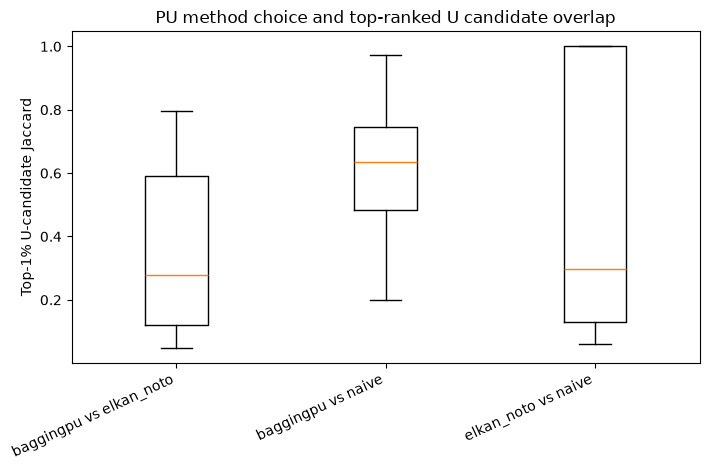

In [20]:
fig, ax = plt.subplots(figsize=(7.3, 4.8))

pairs = (
    method_concordance["method_A"].astype(str)
    + " vs "
    + method_concordance["method_B"].astype(str)
)

plot_df = method_concordance.assign(pair=pairs)
pair_order = sorted(plot_df["pair"].unique())

data = [
    plot_df.loc[
        plot_df["pair"].eq(pair),
        "top_1pct_jaccard",
    ].dropna().to_numpy()
    for pair in pair_order
]

ax.boxplot(
    data,
    tick_labels=pair_order,
    showfliers=False,
)
ax.set_ylabel("Top-1% U-candidate Jaccard")
ax.set_title("PU method choice and top-ranked U candidate overlap")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

# 13. Rank concordance versus top-candidate concordance

In [21]:
display(
    method_concordance[
        [
            "spearman",
            "top_1pct_jaccard",
            "top_5pct_jaccard",
            "mae",
        ]
    ].corr(method="spearman")
)

,spearman,top_1pct_jaccard,top_5pct_jaccard,mae
spearman,1.000000,0.177368,0.930203,-0.717950
top_1pct_jaccard,0.177368,1.000000,0.243804,-0.547108
top_5pct_jaccard,0.930203,0.243804,1.000000,-0.746929
mae,-0.717950,-0.547108,-0.746929,1.000000


High global Spearman does not guarantee identical discovery tails, but **apparent tail disagreement must be separated from unresolved ties**.

For methods with a large boundary plateau, especially Elkan–Noto at U99, the relevant question is not which arbitrary `k` proteins were returned by `nlargest`, but how large the tie-inclusive candidate pool becomes and how strongly that pool overlaps with the alternative method.

# 14. Which method pairs alter the discovery tail most strongly?

In [22]:
tail_instability = (
    method_concordance.assign(
        top1_disagreement=1 - method_concordance["top_1pct_jaccard"],
        top5_disagreement=1 - method_concordance["top_5pct_jaccard"],
    )
    .groupby(["method_A", "method_B"])
    .agg(
        median_top1_disagreement=("top1_disagreement", "median"),
        median_top5_disagreement=("top5_disagreement", "median"),
        fraction_top1_jaccard_lt_050=(
            "top_1pct_jaccard",
            lambda x: (x < 0.50).mean(),
        ),
        fraction_top1_jaccard_lt_025=(
            "top_1pct_jaccard",
            lambda x: (x < 0.25).mean(),
        ),
    )
    .reset_index()
)

display(tail_instability)

,method_A,method_B,median_top1_disagreement,median_top5_disagreement,fraction_top1_jaccard_lt_050,fraction_top1_jaccard_lt_025
0,baggingpu,elkan_noto,0.720508,0.405029,0.667969,0.449219
1,baggingpu,naive,0.365675,0.401588,0.261719,0.050781
2,elkan_noto,naive,0.703758,0.000000,0.632812,0.425781


# 15. BaggingPU internal estimator stability

In [23]:
print("Bagging summary columns:")
print(list(bagging_summary.columns))

if len(bagging_summary) == 0:
    raise RuntimeError("pu_bagging_stability_summary.tsv is empty")

bag_cols = [
    c for c in [
        "n_bags",
        "median_bag_seconds",
        "total_bag_seconds",
        "median_test_score_std",
        "mean_test_score_std",
    ]
    if c in bagging_summary.columns
]

display(
    bagging_summary[bag_cols]
    .describe()
    if bag_cols
    else pd.DataFrame()
)

Bagging summary columns:
['experiment_id', 'task', 'R', 'S', 'representation', 'algorithm', 'n_bags', 'median_bag_seconds', 'total_bag_seconds', 'median_test_score_std', 'mean_test_score_std']


,n_bags,median_bag_seconds,total_bag_seconds,median_test_score_std,mean_test_score_std
count,256.0,256.000000,256.000000,256.000000,256.000000
mean,30.0,5.530109,171.401446,0.028057,0.055605
std,0.0,5.734664,180.062076,0.024781,0.030915
min,30.0,0.112919,3.350915,0.000688,0.011969
25%,30.0,1.903508,62.188958,0.008979,0.030870
50%,30.0,2.995182,90.893594,0.020251,0.050798
75%,30.0,8.006477,242.818877,0.043664,0.076061
max,30.0,24.638377,777.390819,0.105527,0.134657


In [24]:
bagging_overall = {
    "n_families": len(bagging_summary),
}

for c in [
    "n_bags",
    "median_test_score_std",
    "mean_test_score_std",
]:
    if c in bagging_summary.columns:
        bagging_overall[f"{c}_median"] = bagging_summary[c].median()
        bagging_overall[f"{c}_q25"] = bagging_summary[c].quantile(0.25)
        bagging_overall[f"{c}_q75"] = bagging_summary[c].quantile(0.75)

display(pd.DataFrame([bagging_overall]))

,n_families,n_bags_median,n_bags_q25,n_bags_q75,median_test_score_std_median,median_test_score_std_q25,median_test_score_std_q75,mean_test_score_std_median,mean_test_score_std_q25,mean_test_score_std_q75
0,256,30.0,30.0,30.0,0.020251,0.008979,0.043664,0.050798,0.03087,0.076061


Bag-level variability is **internal estimator uncertainty**, not a repeated-seed stability experiment.

Low per-entity bag score variability supports a stable BaggingPU aggregation mechanism; high variability indicates that temporary U-negative sampling materially changes individual scores.

# 16. Does BaggingPU internal variability relate to positive recovery?

In [25]:
bag_native = bagging_summary.merge(
    native[
        native["method"].eq("baggingpu")
    ][
        [
            "experiment_id",
            "median_P_percentile_vs_U",
            "fraction_P_above_U95",
            "fraction_P_above_U99",
        ]
    ],
    on="experiment_id",
    how="inner",
    validate="one_to_one",
)

bag_assoc_rows = []

for variability in [
    c for c in ["median_test_score_std", "mean_test_score_std"]
    if c in bag_native.columns
]:
    for outcome in [
        "median_P_percentile_vs_U",
        "fraction_P_above_U95",
        "fraction_P_above_U99",
    ]:
        g = bag_native[[variability, outcome]].dropna()
        bag_assoc_rows.append({
            "variability": variability,
            "outcome": outcome,
            "n": len(g),
            "spearman_rho": (
                g[variability].corr(g[outcome], method="spearman")
                if len(g) >= 3
                else np.nan
            ),
        })

bagging_associations = pd.DataFrame(bag_assoc_rows)
display(bagging_associations)

,variability,outcome,n,spearman_rho
0,median_test_score_std,median_P_percentile_vs_U,256,-0.713617
1,median_test_score_std,fraction_P_above_U95,256,-0.703104
2,median_test_score_std,fraction_P_above_U99,256,-0.710756
3,mean_test_score_std,median_P_percentile_vs_U,256,-0.388338
4,mean_test_score_std,fraction_P_above_U95,256,-0.391269
5,mean_test_score_std,fraction_P_above_U99,256,-0.388440


# 17. Elkan–Noto propensity behavior

In [26]:
print("Elkan–Noto summary columns:")
print(list(en_summary.columns))

if len(en_summary) == 0:
    raise RuntimeError("pu_elkan_noto_summary.tsv is empty")

display(en_summary.describe(include="all"))

Elkan–Noto summary columns:
['experiment_id', 'task', 'R', 'S', 'representation', 'algorithm', 'c', 'clipping_fraction', 'n_crossfit_folds', 'mean_fold_positive_score', 'min_fold_positive_score', 'max_fold_positive_score']


,experiment_id,task,R,S,representation,algorithm,c,clipping_fraction,n_crossfit_folds,mean_fold_positive_score,min_fold_positive_score,max_fold_positive_score
count,256,256,256.000000,256.000000,256,256,256.000000,256.000000,256.0,256.000000,256.000000,256.000000
unique,256,2,NaN,NaN,4,2,NaN,NaN,NaN,NaN,NaN,NaN
top,PU__pu_broad__R90__S90__roxy_48__elkan_noto__LR,pu_broad,NaN,NaN,roxy_48,LR,NaN,NaN,NaN,NaN,NaN,NaN
freq,1,128,NaN,NaN,64,128,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,60.000000,60.000000,NaN,NaN,0.663212,0.040245,5.0,0.663212,0.640499,0.685124
std,NaN,NaN,22.404481,22.404481,NaN,NaN,0.203833,0.018269,0.0,0.203832,0.206486,0.202295
min,NaN,NaN,30.000000,30.000000,NaN,NaN,0.150036,0.013042,5.0,0.150033,0.125190,0.165080
25%,NaN,NaN,45.000000,45.000000,NaN,NaN,0.519584,0.027165,5.0,0.519590,0.494007,0.538290
50%,NaN,NaN,60.000000,60.000000,NaN,NaN,0.740715,0.036703,5.0,0.740722,0.711499,0.761104
75%,NaN,NaN,75.000000,75.000000,NaN,NaN,0.826256,0.053656,5.0,0.826256,0.802421,0.849951


In [27]:
en_overall = {
    "n_families": len(en_summary),
}

for c in [
    "c",
    "clipping_fraction",
    "n_crossfit_folds",
    "mean_fold_positive_score",
    "min_fold_positive_score",
    "max_fold_positive_score",
]:
    if c in en_summary.columns:
        en_overall[f"{c}_median"] = pd.to_numeric(
            en_summary[c], errors="coerce"
        ).median()
        en_overall[f"{c}_q25"] = pd.to_numeric(
            en_summary[c], errors="coerce"
        ).quantile(0.25)
        en_overall[f"{c}_q75"] = pd.to_numeric(
            en_summary[c], errors="coerce"
        ).quantile(0.75)

display(pd.DataFrame([en_overall]))

,n_families,c_median,c_q25,c_q75,clipping_fraction_median,clipping_fraction_q25,clipping_fraction_q75,n_crossfit_folds_median,n_crossfit_folds_q25,n_crossfit_folds_q75,mean_fold_positive_score_median,mean_fold_positive_score_q25,mean_fold_positive_score_q75,min_fold_positive_score_median,min_fold_positive_score_q25,min_fold_positive_score_q75,max_fold_positive_score_median,max_fold_positive_score_q25,max_fold_positive_score_q75
0,256,0.740715,0.519584,0.826256,0.036703,0.027165,0.053656,5.0,5.0,5.0,0.740722,0.51959,0.826256,0.711499,0.494007,0.802421,0.761104,0.53829,0.849951


# 18. Cross-fit fold spread in propensity estimation

In [28]:
if {
    "min_fold_positive_score",
    "max_fold_positive_score",
} <= set(en_summary.columns):
    en_summary = en_summary.copy()
    en_summary["fold_positive_score_range"] = (
        pd.to_numeric(
            en_summary["max_fold_positive_score"],
            errors="coerce",
        )
        - pd.to_numeric(
            en_summary["min_fold_positive_score"],
            errors="coerce",
        )
    )

    display(
        en_summary["fold_positive_score_range"]
        .describe()
        .to_frame()
    )
else:
    en_summary["fold_positive_score_range"] = np.nan

,fold_positive_score_range
count,256.000000
mean,0.044625
std,0.023521
min,0.007312
25%,0.027912
50%,0.040018
75%,0.060219
max,0.133618


`c` is a labeling-propensity correction parameter, not the biological positive-class prior.

Very small `c`, strong fold-to-fold variation, or extensive score clipping would indicate an unstable correction regime and must be exposed rather than interpreted as improved biological confidence.

# 19. Does Elkan–Noto correction behavior relate to positive recovery?

In [29]:
en_native = en_summary.merge(
    native[
        native["method"].eq("elkan_noto")
    ][
        [
            "experiment_id",
            "median_P_percentile_vs_U",
            "fraction_P_above_U95",
            "fraction_P_above_U99",
        ]
    ],
    on="experiment_id",
    how="inner",
    validate="one_to_one",
)

en_assoc_rows = []

for en_quantity in [
    c for c in [
        "c",
        "clipping_fraction",
        "fold_positive_score_range",
    ]
    if c in en_native.columns
]:
    for outcome in [
        "median_P_percentile_vs_U",
        "fraction_P_above_U95",
        "fraction_P_above_U99",
    ]:
        g = en_native[[en_quantity, outcome]].dropna()
        en_assoc_rows.append({
            "EN_quantity": en_quantity,
            "outcome": outcome,
            "n": len(g),
            "spearman_rho": (
                g[en_quantity].corr(g[outcome], method="spearman")
                if len(g) >= 3 and g[en_quantity].nunique() > 1
                else np.nan
            ),
        })

en_associations = pd.DataFrame(en_assoc_rows)
display(en_associations)

,EN_quantity,outcome,n,spearman_rho
0,c,median_P_percentile_vs_U,256,0.579599
1,c,fraction_P_above_U95,256,0.802898
2,c,fraction_P_above_U99,256,0.880939
3,clipping_fraction,median_P_percentile_vs_U,256,-0.306982
4,clipping_fraction,fraction_P_above_U95,256,-0.736593
5,clipping_fraction,fraction_P_above_U99,256,-0.589992
6,fold_positive_score_range,median_P_percentile_vs_U,256,-0.141155
7,fold_positive_score_range,fraction_P_above_U95,256,-0.059389
8,fold_positive_score_range,fraction_P_above_U99,256,-0.100412


# 20. Score-scale behavior differs by PU method

In [30]:
score_scale_summary = (
    native.groupby("method")
    .agg(
        median_P=("median_P_score", "median"),
        median_U=("median_U_score", "median"),
        median_gap=("median_score_gap_P_minus_U", "median"),
        median_U_q95=("U_q95", "median"),
        median_U_selected_050=("fraction_U_score_ge_050", "median"),
        median_P_selected_050=("fraction_P_score_ge_050", "median"),
    )
    .reindex(METHODS)
)

display(score_scale_summary)

,median_P,median_U,median_gap,median_U_q95,median_U_selected_050,median_P_selected_050
method,,,,,,
naive,0.899342,0.001522,0.855712,0.328609,0.034108,0.780227
baggingpu,0.976879,0.032992,0.940302,0.753438,0.108984,0.883809
elkan_noto,1.000000,0.002225,0.994317,0.547038,0.053280,0.835900


Absolute probability scales are method-dependent.

Especially for Elkan–Noto, correction and clipping can alter the numerical scale without necessarily changing the relative ranking of proteins. Therefore raw threshold-based selection fractions are not treated as the primary method-comparison criterion.

# 21. Recovery gain versus candidate-ranking disruption

In [31]:
# For each matched method pair, combine positive-recovery delta with U-tail overlap.
recovery_pair = native_method_contrasts[
    native_method_contrasts["metric"].eq("fraction_P_above_U95")
][
    MATCH_KEYS
    + ["method_A", "method_B", "delta_B_minus_A"]
].rename(
    columns={
        "delta_B_minus_A": "delta_P_above_U95_B_minus_A"
    }
)

recovery_vs_tail = recovery_pair.merge(
    method_concordance[
        MATCH_KEYS
        + [
            "method_A",
            "method_B",
            "spearman",
            "top_1pct_jaccard",
            "top_5pct_jaccard",
        ]
    ],
    on=MATCH_KEYS + ["method_A", "method_B"],
    how="inner",
    validate="one_to_one",
)

display(
    recovery_vs_tail.groupby(["method_A", "method_B"])
    .agg(
        median_recovery_delta=("delta_P_above_U95_B_minus_A", "median"),
        median_U_spearman=("spearman", "median"),
        median_top1_jaccard=("top_1pct_jaccard", "median"),
        median_top5_jaccard=("top_5pct_jaccard", "median"),
    )
    .reset_index()
)

,method_A,method_B,median_recovery_delta,median_U_spearman,median_top1_jaccard,median_top5_jaccard
0,baggingpu,elkan_noto,0.000344,0.875318,0.279492,0.594971


This directly tests a practically important trade-off:

> Does a PU method improve recovery of known positives while substantially changing which U proteins are prioritized?

For discovery-oriented use, both quantities matter.

# 22. Method-level robustness across the complete benchmark

In [32]:
method_robustness = (
    native.groupby("method")
    .agg(
        p95_recovery_median=("fraction_P_above_U95", "median"),
        p95_recovery_q25=("fraction_P_above_U95", lambda x: x.quantile(0.25)),
        p95_recovery_min=("fraction_P_above_U95", "min"),
        p99_recovery_median=("fraction_P_above_U99", "median"),
        positive_percentile_median=("median_P_percentile_vs_U", "median"),
        positive_percentile_q25=("median_P_percentile_vs_U", lambda x: x.quantile(0.25)),
    )
    .reindex(METHODS)
)

display(method_robustness)

,p95_recovery_median,p95_recovery_q25,p95_recovery_min,p99_recovery_median,positive_percentile_median,positive_percentile_q25
method,,,,,,
naive,0.805159,0.606284,0.201245,0.584050,0.993557,0.969239
baggingpu,0.798217,0.621586,0.413793,0.575905,0.993295,0.970087
elkan_noto,0.805159,0.643916,0.201245,0.683147,1.000000,1.000000


RQ12 uses these benchmark-wide distributions only to characterize method-level consistency.

The explicit R/S response surfaces are reserved for RQ13.

# 23. Practical-tie analysis

In [33]:
# Practical equivalence thresholds are descriptive, not statistical.
# For recovery fractions, ±0.02 corresponds to two percentage points.
TIE_THRESHOLDS = {
    "median_P_percentile_vs_U": 0.02,
    "fraction_P_above_U95": 0.02,
    "fraction_P_above_U99": 0.02,
}

tie_rows = []

for metric, threshold in TIE_THRESHOLDS.items():
    g = native_method_contrasts[
        native_method_contrasts["metric"].eq(metric)
    ]

    for (a, b), grp in g.groupby(["method_A", "method_B"]):
        d = grp["delta_B_minus_A"]
        tie_rows.append({
            "metric": metric,
            "method_A": a,
            "method_B": b,
            "threshold": threshold,
            "fraction_B_better": (d > threshold).mean(),
            "fraction_practical_tie": (d.abs() <= threshold).mean(),
            "fraction_A_better": (d < -threshold).mean(),
        })

practical_ties = pd.DataFrame(tie_rows)
display(practical_ties)

,metric,method_A,method_B,threshold,fraction_B_better,fraction_practical_tie,fraction_A_better
0,median_P_percentile_vs_U,baggingpu,elkan_noto,0.02,0.191406,0.687500,0.121094
1,median_P_percentile_vs_U,naive,baggingpu,0.02,0.121094,0.878906,0.000000
2,median_P_percentile_vs_U,naive,elkan_noto,0.02,0.195312,0.804688,0.000000
3,fraction_P_above_U95,baggingpu,elkan_noto,0.02,0.136719,0.687500,0.175781
4,fraction_P_above_U95,naive,baggingpu,0.02,0.210938,0.761719,0.027344
5,fraction_P_above_U95,naive,elkan_noto,0.02,0.125000,0.875000,0.000000
6,fraction_P_above_U99,baggingpu,elkan_noto,0.02,0.808594,0.191406,0.000000
7,fraction_P_above_U99,naive,baggingpu,0.02,0.191406,0.558594,0.250000
8,fraction_P_above_U99,naive,elkan_noto,0.02,0.675781,0.324219,0.000000


# 24. Compact PU-paradigm evidence table

In [34]:
evidence_rows = []

for method in METHODS:
    g = native[native["method"].eq(method)]

    row = {
        "method": method,
        "n_families": len(g),
        "median_P_percentile_vs_U": g["median_P_percentile_vs_U"].median(),
        "median_fraction_P_above_U95": g["fraction_P_above_U95"].median(),
        "median_fraction_P_above_U99": g["fraction_P_above_U99"].median(),
        "median_score_gap_P_minus_U": g["median_score_gap_P_minus_U"].median(),
        "median_fraction_U_ge_050": g["fraction_U_score_ge_050"].median(),
    }

    if OBS_PRIMARY is not None:
        row["supporting_observed_label_metric"] = OBS_PRIMARY
        row["supporting_observed_label_metric_median"] = (
            master.loc[
                master["method"].eq(method),
                OBS_PRIMARY,
            ].median()
        )

    evidence_rows.append(row)

rq12_method_evidence = pd.DataFrame(evidence_rows)

display(rq12_method_evidence)

,method,n_families,median_P_percentile_vs_U,median_fraction_P_above_U95,median_fraction_P_above_U99,median_score_gap_P_minus_U,median_fraction_U_ge_050,supporting_observed_label_metric,supporting_observed_label_metric_median
0,naive,256,0.993557,0.805159,0.584050,0.855712,0.034108,p_recall_above_u_q90,0.867555
1,baggingpu,256,0.993295,0.798217,0.575905,0.940302,0.108984,p_recall_above_u_q90,0.867149
2,elkan_noto,256,1.000000,0.805159,0.683147,0.994317,0.053280,p_recall_above_u_q90,0.867555


# 25. Pairwise paradigm-shift table

In [35]:
core_pairwise = (
    native_contrast_summary[
        native_contrast_summary["metric"].isin([
            "median_P_percentile_vs_U",
            "fraction_P_above_U95",
            "fraction_P_above_U99",
        ])
    ][
        [
            "metric",
            "method_A",
            "method_B",
            "n",
            "median",
            "q25",
            "q75",
            "fraction_positive",
            "fraction_negative",
        ]
    ]
    .merge(
        practical_ties,
        on=["metric", "method_A", "method_B"],
        how="left",
    )
)

display(core_pairwise)

,metric,method_A,method_B,n,median,q25,q75,fraction_positive,fraction_negative,threshold,fraction_B_better,fraction_practical_tie,fraction_A_better
0,fraction_P_above_U95,baggingpu,elkan_noto,256,0.000344,-0.009889,0.009837,0.500000,0.464844,0.02,0.136719,0.687500,0.175781
1,fraction_P_above_U95,naive,baggingpu,256,0.001180,-0.005568,0.012813,0.527344,0.425781,0.02,0.210938,0.761719,0.027344
2,fraction_P_above_U95,naive,elkan_noto,256,0.000000,0.000000,0.000000,0.148438,0.000000,0.02,0.125000,0.875000,0.000000
3,fraction_P_above_U99,baggingpu,elkan_noto,256,0.088152,0.025958,0.228974,0.925781,0.070312,0.02,0.808594,0.191406,0.000000
4,fraction_P_above_U99,naive,baggingpu,256,-0.002363,-0.019798,0.013139,0.449219,0.539062,0.02,0.191406,0.558594,0.250000
5,fraction_P_above_U99,naive,elkan_noto,256,0.101196,0.000000,0.234299,0.710938,0.000000,0.02,0.675781,0.324219,0.000000
6,median_P_percentile_vs_U,baggingpu,elkan_noto,256,0.003442,0.000911,0.015047,0.867188,0.132812,0.02,0.191406,0.687500,0.121094
7,median_P_percentile_vs_U,naive,baggingpu,256,0.000091,-0.000622,0.000834,0.539062,0.445312,0.02,0.121094,0.878906,0.000000
8,median_P_percentile_vs_U,naive,elkan_noto,256,0.003581,0.000668,0.014100,0.867188,0.000000,0.02,0.195312,0.804688,0.000000


# 26. Candidate-ranking concordance table

In [36]:
candidate_concordance = (
    method_concordance.groupby(["method_A", "method_B"])
    .agg(
        n=("spearman", "size"),
        U_score_spearman_median=("spearman", "median"),
        U_score_spearman_q25=("spearman", lambda x: x.quantile(0.25)),
        U_score_spearman_q75=("spearman", lambda x: x.quantile(0.75)),
        top1pct_jaccard_median=("top_1pct_jaccard", "median"),
        top5pct_jaccard_median=("top_5pct_jaccard", "median"),
        score_MAE_median=("mae", "median"),
    )
    .reset_index()
)

display(candidate_concordance)

,method_A,method_B,n,U_score_spearman_median,U_score_spearman_q25,U_score_spearman_q75,top1pct_jaccard_median,top5pct_jaccard_median,score_MAE_median
0,baggingpu,elkan_noto,256,0.875318,0.789634,0.933747,0.279492,0.594971,0.069379
1,baggingpu,naive,256,0.875318,0.789676,0.933756,0.634325,0.598412,0.074108
2,elkan_noto,naive,256,0.999995,0.999965,1.000000,0.296242,1.000000,0.020701


# 27. RQ12 synthesis questions

After execution, RQ12 should answer:

1. Does BaggingPU improve labeled-positive recovery relative to naive P-vs-U?
2. Does Elkan–Noto improve labeled-positive recovery relative to naive P-vs-U under the **canonical `>=` quantile definition**?
3. How much of U95/U99 recovery is carried by **ties at the U quantile boundary**?
4. Does Elkan–Noto clipping create an unresolved upper-tail plateau?
5. Which dedicated PU method provides the strongest positive recovery after tie structure is exposed?
6. Are the method effects large or dominated by practical ties?
7. Are conclusions broadly consistent across conservative/broad universes and LR/XGB?
8. Do observed-label diagnostics agree with PU-native recovery diagnostics?
9. Do alternative PU methods preserve the same global ranking of U proteins?
10. How much do **tie-inclusive** top-1% and top-5% candidate pools overlap?
11. When fixed-top-k and tie-aware overlap disagree, is the difference explained by score plateaus?
12. Is BaggingPU internally stable across its 30 temporary-negative resamples?
13. Is Elkan–Noto propensity estimation numerically well behaved?
14. Does improved recovery reflect genuine rank separation or primarily score correction/clipping?
15. Does the PU paradigm alter candidate prioritization even when known-positive recovery is similar?

The desired conclusion is **not**:

> “PU method X has the highest biological accuracy.”

The valid conclusion should distinguish:

- recovery of known positives;
- rank separation from U;
- score-scale correction;
- ceiling/tie effects;
- and stability of candidate prioritization.

## Manuscript-level conceptual target

If supported by the corrected analysis:

> **Explicit positive–unlabeled learning changes the predictive score landscape relative to a naive P-vs-U formulation, but different PU strategies do so in different ways. Bagging-based learning can genuinely alter the ranking of unlabeled proteins even when recovery of known positives changes little, whereas propensity correction can largely preserve ranking while changing score scale and creating ceiling ties. Thus, incomplete annotation is not merely a label-quality caveat: the learning paradigm determines both how uncertainty is represented and how candidate-like unlabeled proteins are prioritized.**

Broader methodological point:

> **When absence of annotation is not evidence of absence, treating unlabeled proteins as negatives is itself a modeling assumption whose downstream consequences must be quantified.**

# 28. Export RQ12 cache tables

In [37]:
METHOD_EVIDENCE_PATH = CACHE_DIR / "rq12_pu_method_evidence.tsv"
NATIVE_PATH = CACHE_DIR / "rq12_pu_native_score_diagnostics.tsv"
NATIVE_CONTRAST_PATH = CACHE_DIR / "rq12_pu_native_method_contrasts.tsv"
PAIRWISE_PATH = CACHE_DIR / "rq12_pu_pairwise_paradigm_shift.tsv"
WINNERS_PATH = CACHE_DIR / "rq12_pu_native_winners.tsv"
TASK_PATH = CACHE_DIR / "rq12_pu_task_consistency.tsv"
ALG_PATH = CACHE_DIR / "rq12_pu_algorithm_consistency.tsv"
OBS_PATH = CACHE_DIR / "rq12_pu_observed_label_method_contrasts.tsv"
ALIGN_PATH = CACHE_DIR / "rq12_pu_metric_alignment.tsv"
CONCORDANCE_PATH = CACHE_DIR / "rq12_pu_candidate_concordance.tsv"
TAIL_PATH = CACHE_DIR / "rq12_pu_tail_instability.tsv"
BAG_PATH = CACHE_DIR / "rq12_bagging_stability.tsv"
BAG_ASSOC_PATH = CACHE_DIR / "rq12_bagging_recovery_associations.tsv"
EN_PATH = CACHE_DIR / "rq12_elkan_noto_propensity.tsv"
EN_ASSOC_PATH = CACHE_DIR / "rq12_elkan_noto_recovery_associations.tsv"
RECOVERY_TAIL_PATH = CACHE_DIR / "rq12_recovery_vs_candidate_reordering.tsv"
TIES_PATH = CACHE_DIR / "rq12_pu_practical_ties.tsv"
TIE_AUDIT_PATH = CACHE_DIR / "rq12_pu_quantile_tie_audit.tsv"
TAIL_POOLS_PATH = CACHE_DIR / "rq12_pu_tie_aware_tail_pools.tsv"
TAIL_CONCORDANCE_PATH = CACHE_DIR / "rq12_pu_tie_aware_tail_concordance.tsv"

rq12_method_evidence.to_csv(
    METHOD_EVIDENCE_PATH, sep="\t", index=False
)
native.to_csv(
    NATIVE_PATH, sep="\t", index=False
)
native_method_contrasts.to_csv(
    NATIVE_CONTRAST_PATH, sep="\t", index=False
)
core_pairwise.to_csv(
    PAIRWISE_PATH, sep="\t", index=False
)
native_winners.to_csv(
    WINNERS_PATH, sep="\t", index=False
)
task_consistency.to_csv(
    TASK_PATH, sep="\t", index=False
)
algorithm_consistency.to_csv(
    ALG_PATH, sep="\t", index=False
)
observed_method_contrasts.to_csv(
    OBS_PATH, sep="\t", index=False
)
alignment.to_csv(
    ALIGN_PATH, sep="\t", index=False
)
candidate_concordance.to_csv(
    CONCORDANCE_PATH, sep="\t", index=False
)
tail_instability.to_csv(
    TAIL_PATH, sep="\t", index=False
)
bagging_summary.to_csv(
    BAG_PATH, sep="\t", index=False
)
bagging_associations.to_csv(
    BAG_ASSOC_PATH, sep="\t", index=False
)
en_summary.to_csv(
    EN_PATH, sep="\t", index=False
)
en_associations.to_csv(
    EN_ASSOC_PATH, sep="\t", index=False
)
recovery_vs_tail.to_csv(
    RECOVERY_TAIL_PATH, sep="\t", index=False
)
practical_ties.to_csv(
    TIES_PATH, sep="\t", index=False
)


tie_audit.reset_index().to_csv(
    TIE_AUDIT_PATH, sep="\t", index=False
)

tail_pools_export = tail_pools.drop(
    columns=["inclusive_entity_set"]
)
tail_pools_export.to_csv(
    TAIL_POOLS_PATH, sep="\t", index=False
)

tie_aware_concordance.to_csv(
    TAIL_CONCORDANCE_PATH, sep="\t", index=False
)

print("Saved:")
for p in [
    METHOD_EVIDENCE_PATH,
    NATIVE_PATH,
    NATIVE_CONTRAST_PATH,
    PAIRWISE_PATH,
    WINNERS_PATH,
    TASK_PATH,
    ALG_PATH,
    OBS_PATH,
    ALIGN_PATH,
    CONCORDANCE_PATH,
    TAIL_PATH,
    BAG_PATH,
    BAG_ASSOC_PATH,
    EN_PATH,
    EN_ASSOC_PATH,
    RECOVERY_TAIL_PATH,
    TIES_PATH,
    TIE_AUDIT_PATH,
    TAIL_POOLS_PATH,
    TAIL_CONCORDANCE_PATH,
]:
    print(" ", p)

Saved:
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_pu/notebook_cache/rq12_pu_method_evidence.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_pu/notebook_cache/rq12_pu_native_score_diagnostics.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_pu/notebook_cache/rq12_pu_native_method_contrasts.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_pu/notebook_cache/rq12_pu_pairwise_paradigm_shift.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_pu/notebook_cache/rq12_pu_native_winners.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_pu/notebook_cache/rq12_pu_task_consistency.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_pu/notebook_c

## Final interpretation guardrails

- `U` is unlabeled and may contain undiscovered positives.
- Never call PU observed-label MCC/AP/AUC “biological accuracy”.
- Never interpret lower U scores as automatically biologically better.
- Never interpret a high-scoring U protein as a confirmed positive.
- Naive P-vs-U is a diagnostic baseline, not a valid negative-control formulation.
- BaggingPU's 30 bags are internal estimator fits, not independent repeats.
- Elkan–Noto `c` is labeling propensity, not positive prevalence.
- Probability correction can change score scale; prioritize rank-based comparisons.
- Method comparisons are paired only because task/R/S/representation/algorithm and the native test entities are identical.
- R/S behavior is intentionally deferred to RQ13.
- U-universe breadth is intentionally deferred to RQ14.
- Representation × method interaction is intentionally deferred to RQ15.
- Top-U overlap is a candidate-ranking stability diagnostic, not a biological validation metric.
- Use canonical `>=` quantile recovery to match the frozen trainer; report strict `>` recovery only as a tie-resolution diagnostic.
- Do not interpret fixed-top-k Jaccard as candidate reordering when the score boundary contains a large tie plateau.
- For Elkan–Noto, expose clipping/ceiling mass and prefer tie-aware quantile candidate pools for extreme-tail comparisons.